**Variogram Analysis**
* perform variogram analysis per season to get variogram model and parameters
* parameters to get are - model, sill, range, nugget
* model fit is performed by weighted least square method
* model with least rmse is selected

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
from datetime import datetime
from scipy.optimize import curve_fit

import geostatspy.geostats as geostats
import geostatspy.GSLIB as GSLIB

plt.style.use('default')
pd.set_option('display.max_columns', None)

In [21]:
# --- Section 2: Data Loading and Seasonal Processing ---

def process_data(file, output_path):
    df_insitu_prec = file
    df_insitu_prec['date'] = pd.to_datetime(df_insitu_prec[['year', 'month', 'day']])
    
    # Extract Station Metadata
    df_station = df_insitu_prec[['index_no', 'lat', 'long']].drop_duplicates().reset_index(drop=True)
    
    # Define Seasons
    seasons = {
        'winter': [12, 1, 2],
        'pre_monsoon': [3, 4, 5],
        'monsoon': [6, 7, 8, 9],
        'post_monsoon': [10, 11]
    }

    # Map Seasons
    df_seasonal = df_insitu_prec.copy()
    df_seasonal['season'] = df_seasonal['month'].map(lambda x: [k for k, v in seasons.items() if x in v][0])
    df_seasonal = df_seasonal[['index_no', 'lat', 'long', 'rainfall_sum', 'date', 'season']]
    df_seasonal['year'] = df_seasonal['date'].dt.year
    df_seasonal['month'] = df_seasonal['date'].dt.month

    # Adjust Year for Winter (Dec belongs to following year's season)
    df_seasonal['year_seasonal'] = df_seasonal['year']
    df_seasonal.loc[df_seasonal['month'] == 12, 'year_seasonal'] = df_seasonal.loc[df_seasonal['month'] == 12, 'year'] + 1

    # Aggregate Data
    # 1. Sum rainfall per station per season per year
    df_seasonal_sum = df_seasonal.groupby(by=['index_no', 'season', 'year_seasonal'])[['rainfall_sum']].sum().reset_index()
    
    # 2. Average the sums across all years for each station/season
    df_seasonal_averaged = df_seasonal_sum.groupby(by=['season', 'index_no'])[['rainfall_sum']].mean().reset_index()
    df_seasonal_averaged = df_seasonal_averaged.round(2)

    # Save intermediate if needed
    if output_path:
        df_seasonal_averaged.to_csv(output_path, index=False)

    # Merge Coordinates back
    df_final = pd.merge(df_seasonal_averaged, df_station, on='index_no', how='left')
    df_final = df_final[['index_no', 'lat', 'long', 'season', 'rainfall_sum']]
    
    return df_final

# Execute Data Loading
insitu_total_df = pd.read_csv(r"..\Data\Processed\Insitu\insitu_rainfall_1991_2020.csv")

#filter for train stations
train_stations_df = pd.read_csv(r"..\Data\Processed\Split_stations\train_stations.csv")
train_stations = train_stations_df['index_no'].tolist()

insitu_total_df = insitu_total_df[insitu_total_df['index_no'].isin(train_stations)]
output_file = r"..\Data\Processed\Variogram_analysis\seasonal_averaged.csv"

df_all_seasons = process_data(insitu_total_df, output_file)
print("Data processed. Head:")
print(df_all_seasons.head())

Data processed. Head:
   index_no       lat      long   season  rainfall_sum
0       107  29.84496  80.54539  monsoon       2005.89
1       203  29.26804  80.98360  monsoon        940.25
2       215  28.87623  80.57919  monsoon       2061.86
3       217  29.13611  81.25009  monsoon       1037.25
4       306  29.55031  82.15428  monsoon        587.27


In [22]:
# --- Section 3: Variogram Model Definitions & Fitting Logic ---

def gaussian_model(h, nugget, psill, range_val):
    return nugget + psill * (1 - np.exp(-(h / range_val)**2))

def spherical_model(h, nugget, psill, range_val):
    val = np.zeros_like(h)
    idx = h <= range_val
    val[idx] = nugget + psill * (1.5 * (h[idx]/range_val) - 0.5 * (h[idx]/range_val)**3)
    val[~idx] = nugget + psill
    return val

def exponential_model(h, nugget, psill, range_val):
    return nugget + psill * (1 - np.exp(-h / range_val))

def prepare_wls_weights(lag, gamma):
    """Clean data and compute WLS weights (1/h^2)"""
    valid = np.isfinite(gamma) & np.isfinite(lag)
    lag_c, gamma_c = lag[valid], gamma[valid]
    
    # Remove zero lag
    mask = lag_c > 0
    lag_c, gamma_c = lag_c[mask], gamma_c[mask]
    
    if len(lag_c) == 0:
        return np.array([]), np.array([]), np.array([])

    # Weights: inverse square of lag
    weights = 1.0 / (lag_c**2)
    weights[~np.isfinite(weights)] = 1.0
    
    # Return sigma (1/sqrt(weights)) for curve_fit
    return lag_c, gamma_c, 1.0 / np.sqrt(weights)

def fit_variogram_model(model_func, lag_c, gamma_c, sigma, p0=[0, 1, 1.5]):
    """Fit a specific model and return metrics"""
    # Bounds: nugget >= 0, sill >= 0, range >= small_epsilon
    bounds = ([0, 0, 1e-6], [np.inf, np.inf, np.inf])
    try:
        popt, _ = curve_fit(model_func, lag_c, gamma_c, p0=p0, 
                            bounds=bounds, sigma=sigma, absolute_sigma=True, maxfev=10000)
        
        residuals = gamma_c - model_func(lag_c, *popt)
        weights = 1 / sigma**2
        wrss = np.sum(weights * residuals**2)
        rmse = np.sqrt(np.mean(residuals**2))
        
        return popt, rmse, wrss
    except Exception:
        return None, None, None

In [23]:
# --- Section 4: Main Analysis Module ---

def perform_seasonal_analysis(df_input, season_name, lag_dist, lag_tol, nlag):
    """
    Executes the full variogram analysis workflow for a specific season.
    1. Data Prep & Nscore
    2. Visualization (Histograms & Maps)
    3. Experimental Variogram (GAMV)
    4. Model Fitting & Comparison
    """
    print(f"\n{'='*30}")
    print(f"ANALYSIS FOR: {season_name.upper()}")
    print(f"{'='*30}")

    # 1. Filter Data & NScore Transform
    df_subset = df_input[df_input['season'] == season_name].copy()
    df_subset['n_prec'], _, _ = geostats.nscore(df_subset, 'rainfall_sum')

    # Calculate average spacing (sanity check)
    lat_spacing = np.mean(np.diff(np.sort(df_subset['lat'].values)))
    lon_spacing = np.mean(np.diff(np.sort(df_subset['long'].values)))
    print(f"Avg Lat Spacing: {lat_spacing:.4f}° | Avg Lon Spacing: {lon_spacing:.4f}°")

    # 2. Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    
    # Histogram: Raw
    axes[0,0].hist(df_subset['rainfall_sum'], bins=30, color='skyblue', edgecolor='black')
    axes[0,0].set_title(f"Rainfall Distribution - {season_name}")
    
    # Histogram: NScore
    axes[0,1].hist(df_subset['n_prec'], bins=30, color='salmon', edgecolor='black')
    axes[0,1].set_title(f"Normalized rainfall - {season_name}")
    
    # Location Map
    # Note: Using scatter directly for cleaner modularity, mimicking GSLIB locmap
    sc = axes[1,0].scatter(df_subset['lat'], df_subset['long'], c=df_subset['n_prec'], 
                           cmap='plasma', s=30, edgecolors='k', linewidth=0.5)
    axes[1,0].set_title("Station Locations & NScore")
    axes[1,0].set_xlabel("Latitude")
    axes[1,0].set_ylabel("Longitude")
    plt.colorbar(sc, ax=axes[1,0], label='Nscore Rainfall')
    
    axes[1,1].axis('off') # Empty quadrant
    plt.tight_layout()
    plt.show()

    # 3. Experimental Variogram (GAMV)
    # Parameters logic retained from original code:
    # nlag ~ 85, bandh ~ inf, azi=0, atol=90 (isotropic)
    tmin, tmax = -9999, 9999
    #nlag = 85
    bandh = 9999.9
    azi = 0
    atol = 90
    isill = 1

    print(f"GAMV Params -> Lag: {lag_dist}, Tol: {lag_tol}, NLag: {nlag}")
    
    lag_exp, gamma_exp, _ = geostats.gamv(
        df_subset, 'lat', 'long', 'rainfall_sum', 
        tmin, tmax, lag_dist, lag_tol, nlag, azi, atol, bandh, isill
    )

    # Plot Experimental
    plt.figure(figsize=(8, 5))
    plt.plot(lag_exp, gamma_exp, '.', color='black', label='Experimental')
    plt.axhline(y=1, color='green', linestyle='--', label='Sill (Normalized)')
    plt.title(f"Experimental Variogram - {season_name}")
    plt.xlabel("Lag Distance")
    plt.ylabel("Semivariance")
    plt.legend()
    plt.show()

    # 4. Model Fitting
    lag_c, gamma_c, sigma = prepare_wls_weights(lag_exp, gamma_exp)
    
    models = {
        'Gaussian': gaussian_model,
        'Spherical': spherical_model,
        'Exponential': exponential_model
    }
    
    colors = {'Gaussian': 'blue', 'Spherical': 'green', 'Exponential': 'red'}
    
    # Plot Comparison
    plt.figure(figsize=(10, 6))
    plt.scatter(lag_c, gamma_c, c='black', marker='.', s=50, label='Experimental', zorder=10)
    h_fit = np.linspace(0, max(lag_c), 200)

    print(f"\n{season_name.upper()} MODEL RESULTS:")
    print(f"{'Model':<12} {'Nugget':<10} {'PSill':<10} {'Range':<10} {'RMSE':<10} {'WRSS':<10}")
    print("-" * 65)

    for name, func in models.items():
        popt, rmse, wrss = fit_variogram_model(func, lag_c, gamma_c, sigma)
        
        if popt is not None:
            nugget, psill, range_val = popt
            print(f"{name:<12} {nugget:<10.4f} {psill:<10.4f} {range_val:<10.4f} {rmse:<10.4f} {wrss:<10.4f}")
            plt.plot(h_fit, func(h_fit, *popt), color=colors[name], lw=2, label=f"{name} (RMSE={rmse:.3f})")
        else:
            print(f"{name:<12} Fit Failed")

    plt.xlabel('Lag Distance')
    plt.ylabel('Semivariance')
    plt.title(f'Variogram Model Comparison - {season_name}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


ANALYSIS FOR: WINTER
Avg Lat Spacing: 0.0686° | Avg Lon Spacing: 0.1534°


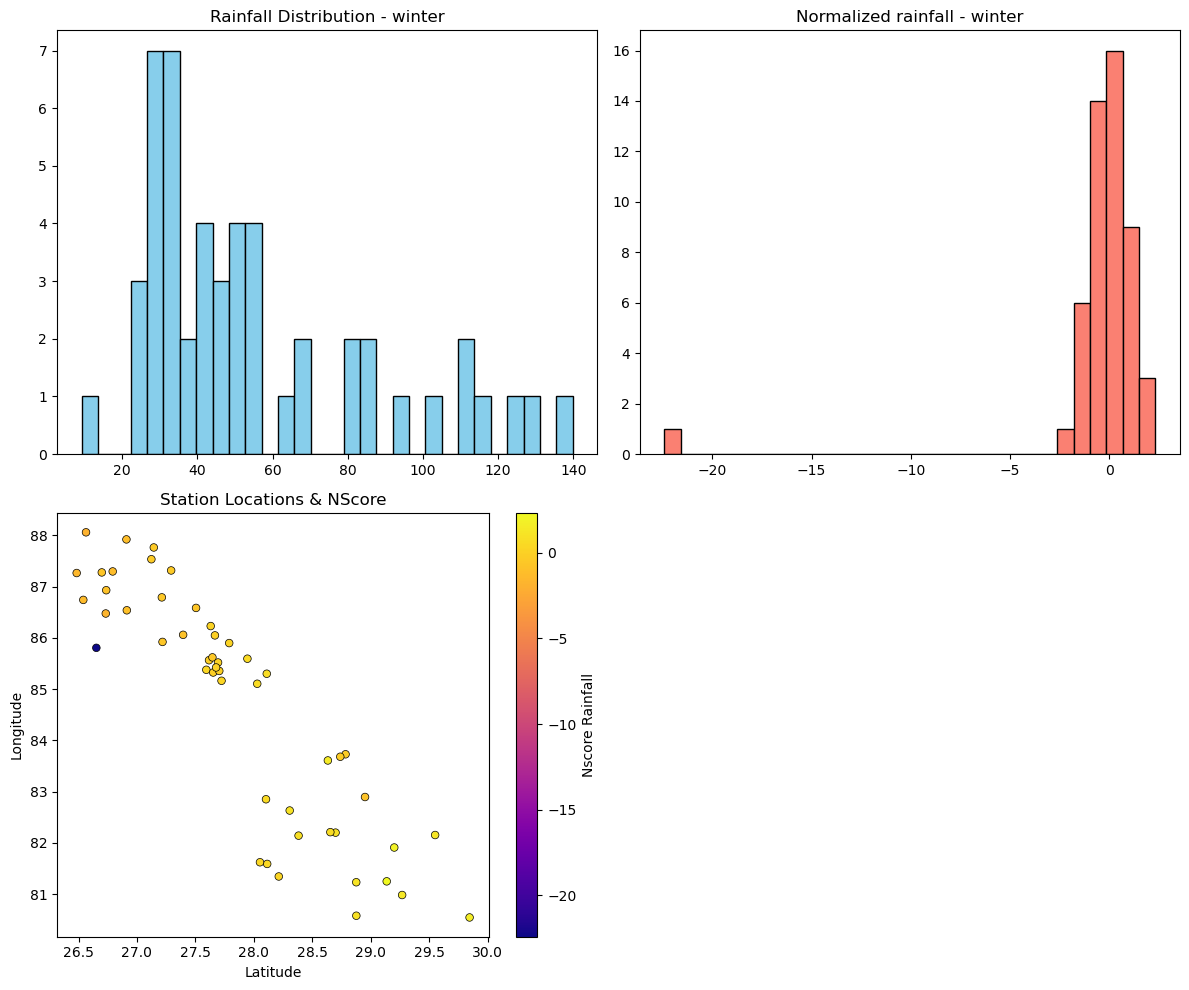

GAMV Params -> Lag: 0.1, Tol: 0.05, NLag: 100


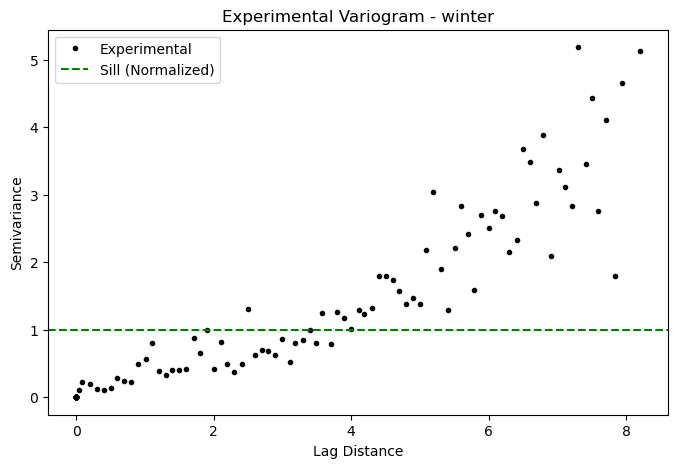


WINTER MODEL RESULTS:
Model        Nugget     PSill      Range      RMSE       WRSS      
-----------------------------------------------------------------
Gaussian     0.1396     5.6055     7.8901     0.5121     2.5929    
Spherical    0.1129     7457.4125  33752.5656 0.6927     2.6011    
Exponential  0.1129     4450.4555  13426.7370 0.6928     2.6014    


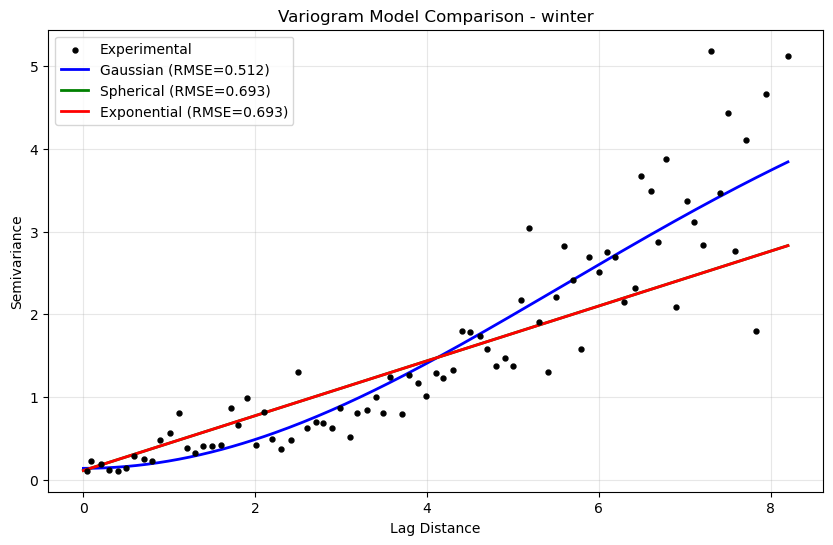

In [24]:
# --- Section 5: Execution Loop for All Seasons ---

# Configuration dictionary for season-specific GAMV parameters.
# Values are derived based on data density and trial-and-error optimization logic.
# Lag distance usually approx 0.06 - 0.08 based on average lat/lon spacing.
season_params = {
    'winter':       {'lag_dist': 0.10, 'lag_tol': 0.05, 'n_lag': 100},
    'pre_monsoon':  {'lag_dist': 0.075, 'lag_tol': 0.0375, 'n_lag': 10},
    'monsoon':      {'lag_dist': 0.078, 'lag_tol': 0.05, 'n_lag': 90},  # tuned
    'post_monsoon': {'lag_dist': 0.060, 'lag_tol': 0.030, 'n_lag': 10}   # From original code
}

# Iterate through all seasons
#for season, params in season_params.items():
    # perform_seasonal_analysis(
    #     df_all_seasons, 
    #     season, 
    #     params['lag_dist'], 
    #     params['lag_tol'],
    #     params['n_lag']
    # )
perform_seasonal_analysis(df_all_seasons, 'winter', season_params['winter']['lag_dist'], season_params['winter']['lag_tol'], season_params['winter']['n_lag'])